# 07 — Activity Classification with IMU Deep Learning

This notebook performs **6-class activity classification** as a separate Deep Learning task.

## Classes
- Eating
- High Tempo Cycling
- Low Tempo Cycling
- Sitting
- Sleep
- Walking

## Input
Only the accelerometer channels are used:

- `ACC_X`
- `ACC_Y`
- `ACC_Z`

Input shape: `(N, 320, 3)`

Using IMU-only input makes this a clean activity-recognition experiment based on motion rather than letting the classifier rely on heart-rate level.

## Data policy
The notebook reuses the exact same:
- 8-second windows
- timing QC
- recording-session boundaries
- chronological 70 / 15 / 15 split

Nothing is saved to disk.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Re-run the final preprocessing pipeline

In [2]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Prepare IMU Inputs and Activity Labels

`X_fusion_*` contains:

`[PPG_Raw, ACC_X, ACC_Y, ACC_Z]`

For activity classification we keep only the three accelerometer channels.

In [3]:
X_acc_train = X_fusion_train[:, :, 1:4]
X_acc_val   = X_fusion_val[:, :, 1:4]
X_acc_test  = X_fusion_test[:, :, 1:4]

activity_to_id = {
    activity: idx
    for idx, activity in enumerate(ACTIVITY_ORDER)
}

id_to_activity = {
    idx: activity
    for activity, idx in activity_to_id.items()
}

y_activity_train = meta_train["Activity"].map(activity_to_id).to_numpy(dtype=np.int32)
y_activity_val   = meta_val["Activity"].map(activity_to_id).to_numpy(dtype=np.int32)
y_activity_test  = meta_test["Activity"].map(activity_to_id).to_numpy(dtype=np.int32)

print("Train:", X_acc_train.shape, y_activity_train.shape)
print("Val  :", X_acc_val.shape, y_activity_val.shape)
print("Test :", X_acc_test.shape, y_activity_test.shape)

assert X_acc_train.shape[1:] == (320, 3)
assert len(y_activity_train) == len(X_acc_train)
assert len(y_activity_val) == len(X_acc_val)
assert len(y_activity_test) == len(X_acc_test)

print()
print("Class mapping:")
for class_id, activity in id_to_activity.items():
    print(f"{class_id}: {activity}")

Train: (1322, 320, 3) (1322,)
Val  : (281, 320, 3) (281,)
Test : (292, 320, 3) (292,)

Class mapping:
0: Eating
1: High_Tempo_Cycling
2: Low_Tempo_Cycling
3: Sitting
4: Sleep
5: Walking


## 4. Class Distribution

,Train,Validation,Test
Activity,,,
Eating,33,7,8
High_Tempo_Cycling,171,36,38
Low_Tempo_Cycling,255,54,56
Sitting,191,40,43
Sleep,337,72,73
Walking,335,72,74


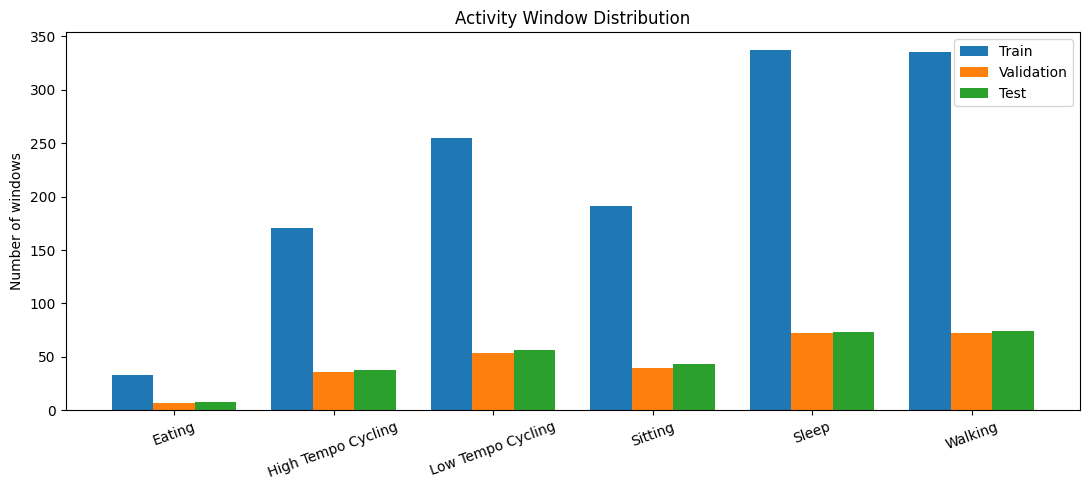

In [4]:
split_counts = pd.DataFrame({
    "Train": pd.Series(meta_train["Activity"]).value_counts(),
    "Validation": pd.Series(meta_val["Activity"]).value_counts(),
    "Test": pd.Series(meta_test["Activity"]).value_counts(),
}).reindex(ACTIVITY_ORDER).fillna(0).astype(int)

display(split_counts)

plt.figure(figsize=(11, 5))
x = np.arange(len(ACTIVITY_ORDER))
width = 0.26

plt.bar(x - width, split_counts["Train"], width, label="Train")
plt.bar(x, split_counts["Validation"], width, label="Validation")
plt.bar(x + width, split_counts["Test"], width, label="Test")

plt.xticks(
    x,
    [a.replace("_", " ") for a in ACTIVITY_ORDER],
    rotation=20
)
plt.ylabel("Number of windows")
plt.title("Activity Window Distribution")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Training-Only IMU Normalization

Each accelerometer axis is normalized separately using **training-set statistics only**.

Validation and test inputs use the same training mean and standard deviation.

In [5]:
acc_mean = X_acc_train.mean(
    axis=(0, 1),
    keepdims=True
)

acc_std = X_acc_train.std(
    axis=(0, 1),
    keepdims=True
)

if np.any(acc_std == 0):
    raise ValueError("At least one accelerometer axis has zero standard deviation.")

X_acc_train_norm = (
    X_acc_train - acc_mean
) / acc_std

X_acc_val_norm = (
    X_acc_val - acc_mean
) / acc_std

X_acc_test_norm = (
    X_acc_test - acc_mean
) / acc_std

normalization_table = pd.DataFrame({
    "Channel": ["ACC_X", "ACC_Y", "ACC_Z"],
    "Train_Mean": acc_mean.reshape(-1),
    "Train_Std": acc_std.reshape(-1),
    "Normalized_Train_Mean": X_acc_train_norm.mean(axis=(0, 1)),
    "Normalized_Train_Std": X_acc_train_norm.std(axis=(0, 1)),
})

display(normalization_table.round(5))

,Channel,Train_Mean,Train_Std,Normalized_Train_Mean,Normalized_Train_Std
0,ACC_X,-0.32539,0.55772,-0.00000,1.00000
1,ACC_Y,0.34338,0.23384,0.00004,0.99999
2,ACC_Z,-0.67551,0.31986,0.00006,0.99999


## 6. Class Weights

The dataset is imbalanced; for example, Eating has many fewer windows than Sleep or Walking.

Class weights are calculated from the **training split only** so minority activities contribute more fairly to the training loss.

In [6]:
classes = np.arange(len(ACTIVITY_ORDER))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_activity_train
)

class_weight = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

class_weight_table = pd.DataFrame({
    "Class_ID": classes,
    "Activity": [id_to_activity[i] for i in classes],
    "Weight": weights,
})

display(class_weight_table.round(3))

,Class_ID,Activity,Weight
0,0,Eating,6.677
1,1,High_Tempo_Cycling,1.288
2,2,Low_Tempo_Cycling,0.864
3,3,Sitting,1.154
4,4,Sleep,0.654
5,5,Walking,0.658


## 7. Reproducibility

In [7]:
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 8. Build the 1D CNN Activity Classifier

The model learns temporal movement patterns from the three accelerometer axes.

Output uses a 6-class Softmax layer.

In [8]:
def build_activity_classifier():
    inputs = tf.keras.layers.Input(
        shape=(320, 3),
        name="imu_input"
    )

    x = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)

    x = tf.keras.layers.Conv1D(
        64,
        kernel_size=5,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)

    x = tf.keras.layers.Conv1D(
        128,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dropout(0.30)(x)

    x = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(0.20)(x)

    outputs = tf.keras.layers.Dense(
        len(ACTIVITY_ORDER),
        activation="softmax",
        name="activity_probabilities"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="IMU_Activity_1D_CNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


activity_model = build_activity_classifier()
activity_model.summary()

Model: "IMU_Activity_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imu_input (InputLayer)          │ (None, 320, 3)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 320, 32)        │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 320, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 160, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 160, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 80, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_probabilities (Dense)  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,742 (174.77 KB)

 Trainable params: 44,550 (174.02 KB)

 Non-trainable params: 192 (768.00 B)

## 9. Training Callbacks

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1,
    ),
]

## 10. Train the Activity Classifier

In [10]:
history = activity_model.fit(
    X_acc_train_norm,
    y_activity_train,

    validation_data=(
        X_acc_val_norm,
        y_activity_val
    ),

    epochs=150,
    batch_size=32,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8729 - loss: 0.4292 - val_accuracy: 0.7295 - val_loss: 1.1731 - learning_rate: 0.0010
Epoch 2/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9304 - loss: 0.2317 - val_accuracy: 0.7224 - val_loss: 0.8597 - learning_rate: 0.0010
Epoch 3/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9342 - loss: 0.1941 - val_accuracy: 0.7224 - val_loss: 0.7536 - learning_rate: 0.0010
Epoch 4/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9486 - loss: 0.1381 - val_accuracy: 0.7331 - val_loss: 0.6210 - learning_rate: 0.0010
Epoch 5/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9561 - loss: 0.1417 - val_accuracy: 0.7651 - val_loss: 0.5358 - learning_rate: 0.0010
Epoch 6/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9607 - loss: 0.1274 - val_accuracy: 0.8221 - val_loss: 0.3976 - learning_rate: 0.0010
Epoch 7/150
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9569 - loss: 0.1141 - val_ac

## 11. Training History

Epochs trained: 23
Best epoch    : 8


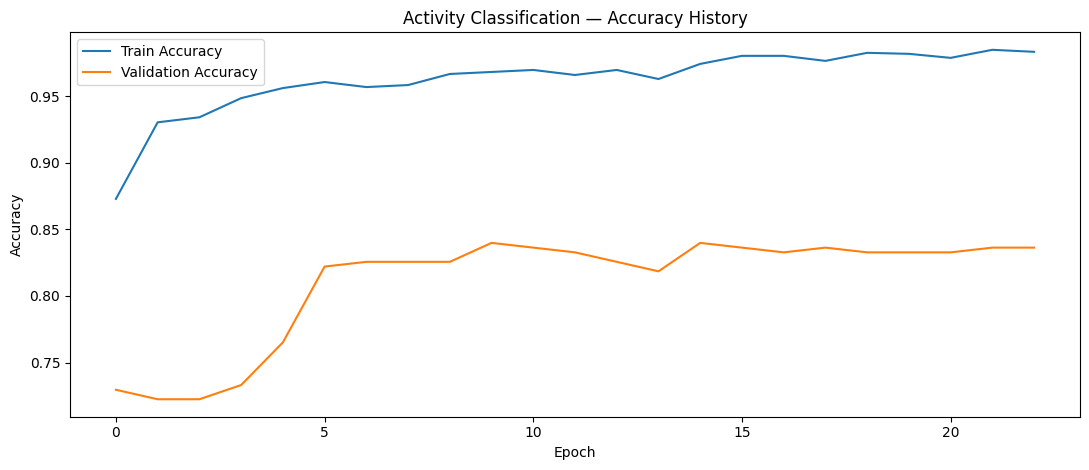

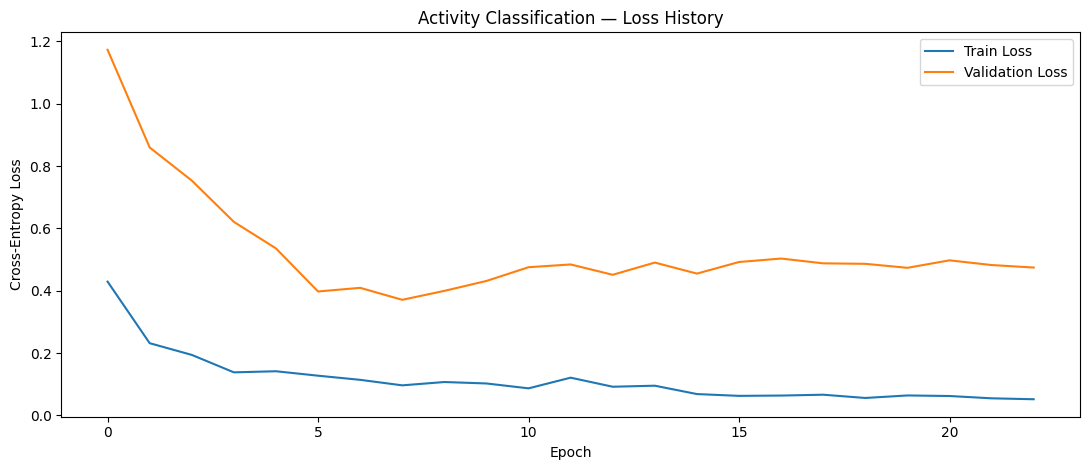

In [11]:
history_df = pd.DataFrame(history.history)

best_epoch = int(
    history_df["val_loss"].idxmin()
    + 1
)

print("Epochs trained:", len(history_df))
print("Best epoch    :", best_epoch)

plt.figure(figsize=(11, 4.8))
plt.plot(history_df["accuracy"], label="Train Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Activity Classification — Accuracy History")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4.8))
plt.plot(history_df["loss"], label="Train Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Activity Classification — Loss History")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Test Predictions

In [12]:
test_probabilities = activity_model.predict(
    X_acc_test_norm,
    verbose=0
)

y_activity_pred = np.argmax(
    test_probabilities,
    axis=1
)

print("Predictions:", y_activity_pred.shape)

Predictions: (292,)


## 13. Overall Classification Metrics

For this task, unlike HR regression, **accuracy is a valid metric**.

Because class sizes are unequal, we also report:
- Balanced Accuracy
- Macro F1
- Weighted F1


In [13]:
test_accuracy = accuracy_score(
    y_activity_test,
    y_activity_pred
)

balanced_acc = balanced_accuracy_score(
    y_activity_test,
    y_activity_pred
)

macro_f1 = f1_score(
    y_activity_test,
    y_activity_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_activity_test,
    y_activity_pred,
    average="weighted"
)

overall_metrics = pd.DataFrame([{
    "Accuracy": test_accuracy,
    "Balanced_Accuracy": balanced_acc,
    "Macro_F1": macro_f1,
    "Weighted_F1": weighted_f1,
}])

display(overall_metrics.round(4))

print(f"Test Accuracy         : {test_accuracy * 100:.2f}%")
print(f"Balanced Accuracy     : {balanced_acc * 100:.2f}%")
print(f"Macro F1              : {macro_f1:.4f}")
print(f"Weighted F1           : {weighted_f1:.4f}")

,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1
0,0.8836,0.887,0.8826,0.8842


Test Accuracy         : 88.36%
Balanced Accuracy     : 88.70%
Macro F1              : 0.8826
Weighted F1           : 0.8842


## 14. Per-Class Precision, Recall and F1

In [14]:
report = classification_report(
    y_activity_test,
    y_activity_pred,
    labels=classes,
    target_names=[
        activity.replace("_", " ")
        for activity in ACTIVITY_ORDER
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(
    report_df.round(3)
)

,precision,recall,f1-score,support
Eating,1.000,1.000,1.000,8.000
High Tempo Cycling,0.600,0.789,0.682,38.000
Low Tempo Cycling,0.818,0.643,0.720,56.000
Sitting,0.952,0.930,0.941,43.000
Sleep,0.973,1.000,0.986,73.000
Walking,0.973,0.959,0.966,74.000
accuracy,0.884,0.884,0.884,0.884
macro avg,0.886,0.887,0.883,292.000
weighted avg,0.892,0.884,0.884,292.000


## 15. Confusion Matrix — Raw Counts

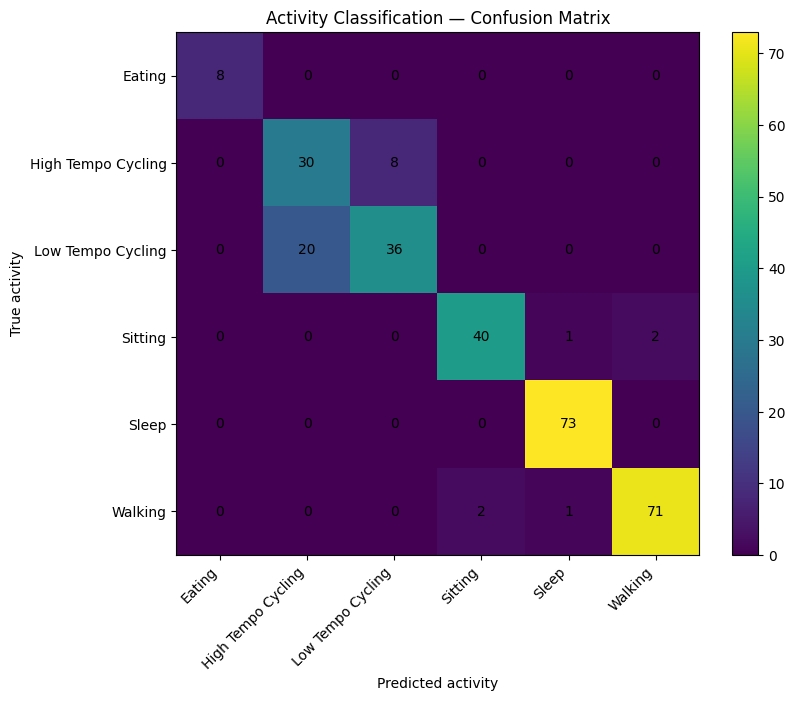

In [15]:
cm = confusion_matrix(
    y_activity_test,
    y_activity_pred,
    labels=classes
)

plt.figure(figsize=(8.5, 7))

plt.imshow(cm)
plt.colorbar()

tick_labels = [
    activity.replace("_", " ")
    for activity in ACTIVITY_ORDER
]

plt.xticks(
    np.arange(len(classes)),
    tick_labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(classes)),
    tick_labels
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("Activity Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

## 16. Confusion Matrix — Row-Normalized

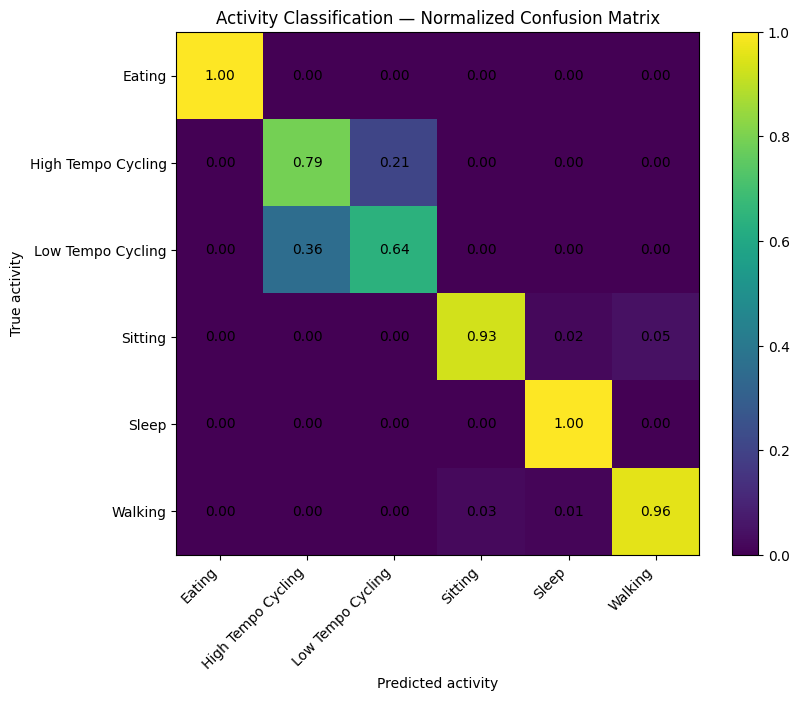

In [16]:
cm_normalized = cm.astype(float) / cm.sum(
    axis=1,
    keepdims=True
)

plt.figure(figsize=(8.5, 7))

plt.imshow(
    cm_normalized,
    vmin=0,
    vmax=1
)

plt.colorbar()

plt.xticks(
    np.arange(len(classes)),
    tick_labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(classes)),
    tick_labels
)

for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):
        plt.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("Activity Classification — Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

## 17. Per-Activity Test Accuracy

,Activity,Test_Windows,Correct,Accuracy
0,Eating,8,8,1.000
1,High_Tempo_Cycling,38,30,0.789
2,Low_Tempo_Cycling,56,36,0.643
3,Sitting,43,40,0.930
4,Sleep,73,73,1.000
5,Walking,74,71,0.959


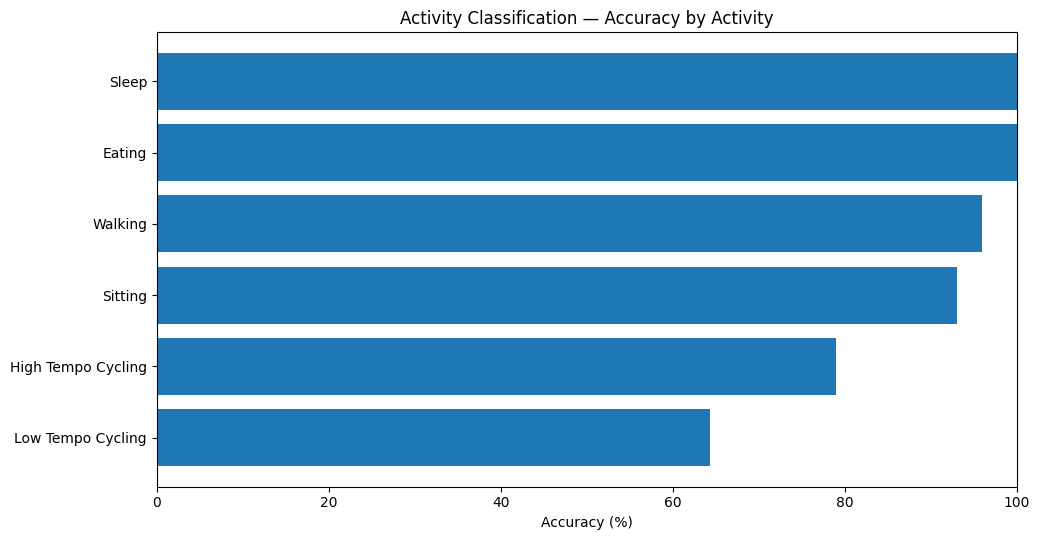

In [17]:
per_activity_rows = []

for class_id, activity in id_to_activity.items():
    mask = y_activity_test == class_id

    if not np.any(mask):
        continue

    correct = (
        y_activity_pred[mask]
        == y_activity_test[mask]
    )

    per_activity_rows.append({
        "Activity": activity,
        "Test_Windows": int(mask.sum()),
        "Correct": int(correct.sum()),
        "Accuracy": float(correct.mean()),
    })

per_activity_accuracy = pd.DataFrame(
    per_activity_rows
)

display(
    per_activity_accuracy.round(3)
)

plot_df = per_activity_accuracy.sort_values(
    "Accuracy"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df["Activity"].str.replace("_", " "),
    plot_df["Accuracy"] * 100
)

plt.xlabel("Accuracy (%)")
plt.title("Activity Classification — Accuracy by Activity")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 18. Prediction Confidence

This section shows how confident the Softmax classifier is on the test set.

High confidence does not automatically mean a prediction is correct, but it is useful for diagnostics.

In [18]:
prediction_confidence = np.max(
    test_probabilities,
    axis=1
)

correct_mask = (
    y_activity_pred
    == y_activity_test
)

confidence_summary = pd.DataFrame({
    "Group": [
        "All test windows",
        "Correct predictions",
        "Incorrect predictions",
    ],
    "Mean_Confidence": [
        prediction_confidence.mean(),
        prediction_confidence[correct_mask].mean()
        if np.any(correct_mask) else np.nan,
        prediction_confidence[~correct_mask].mean()
        if np.any(~correct_mask) else np.nan,
    ],
})

display(
    confidence_summary.round(3)
)

,Group,Mean_Confidence
0,All test windows,0.905
1,Correct predictions,0.934
2,Incorrect predictions,0.687


## 19. No Saving

This notebook intentionally saves nothing.

No:
- `.keras` model
- CSV
- PNG
- NPZ
- prediction file

is written to disk.

Once the final project pipeline is complete, final artifacts will be saved together.

## 20. What to Send for Review

After running the notebook, send:

1. Test Accuracy / Balanced Accuracy / Macro F1
2. Per-class classification report
3. Raw or normalized confusion matrix
4. Per-activity accuracy table
5. Training accuracy graph

Then we can decide whether one activity classifier is enough or whether a second classifier architecture is worth testing.